# Predicting data science salaries: from a messy first pass to a defensible model

A redo of the PSTAT 131 R project (`main.Rmd`). The questions here:

1. How much of the original result survives honest evaluation, and what does each cleaning and optimization step buy?
2. Which model is best, decided by a rule fixed *before* looking at the results?
3. What can a business actually do with a model like this?

Every number below comes from `outputs/` (written by `experiments.py` and `insights.py`), under one protocol: 5-fold cross-validation repeated 3 times, cleaning learned on training folds only, scores always computed on untouched held-out rows.

In [1]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.ticker import FuncFormatter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import Markdown, display

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'axes.titleweight': 'bold', 'axes.titlesize': 11})
BLUE, RED, GREY, GOLD, GREEN = '#2f6fed', '#d1495b', '#95a0b0', '#f0b429', '#1f9d6b'
OUT = 'outputs'
stage = pd.read_csv(f'{OUT}/stage_results.csv')
search = pd.read_csv(f'{OUT}/model_search.csv')
decision = json.load(open(f'{OUT}/decision.json'))
ins = json.load(open(f'{OUT}/insights.json'))
oof = np.load(f'{OUT}/stage_oof.npz', allow_pickle=True)

from experiments import raw_data, dedup_data, build
from features import TARGET, CAT_RAW, NUM_RAW
raw, dedup = raw_data(), dedup_data()
usd = lambda v: f'${v:,.0f}'
kfmt = FuncFormatter(lambda v, _: f'${v/1000:,.0f}k')
print(f'{len(raw):,} raw rows -> {len(dedup):,} after removing exact duplicates')

3,755 raw rows -> 2,583 after removing exact duplicates


In [2]:
s = stage.set_index(['family', 'stage'])
best_row = stage[stage.stage == 5].iloc[0]
best_name = decision['accuracy_winner'].split('_', 1)[1]
display(Markdown(f'''### Headline
- **The R-style setup looked better than it was.** Random forest on the raw data scored R\u00b2 **{s.loc[('RF',0),'r2']:.2f}** / RMSE **{usd(s.loc[('RF',0),'rmse'])}**, but 31% of rows were duplicates leaking across train and test.
- **Honest baseline:** after deduplicating, the same model scores R\u00b2 **{s.loc[('RF',1),'r2']:.2f}** / RMSE **{usd(s.loc[('RF',1),'rmse'])}**.
- **After cleaning, features and tuning** the best random forest reaches R\u00b2 **{s.loc[('RF',4),'r2']:.2f}** and the best boosted model R\u00b2 **{s.loc[('LGBM',4),'r2']:.2f}**. The overall winner, **{best_name}**, reaches R\u00b2 **{best_row.r2:.2f}** / RMSE **{usd(best_row.rmse)}**.
- **The ceiling is the data, not the method:** the model sees seven columns, and people with identical profiles differ in salary by about 30% (section 4).
'''))

### Headline
- **The R-style setup looked better than it was.** Random forest on the raw data scored R² **0.40** / RMSE **$48,832**, but 31% of rows were duplicates leaking across train and test.
- **Honest baseline:** after deduplicating, the same model scores R² **0.39** / RMSE **$52,356**.
- **After cleaning, features and tuning** the best random forest reaches R² **0.40** and the best boosted model R² **0.41**. The overall winner, **Stacking**, reaches R² **0.41** / RMSE **$51,366**.
- **The ceiling is the data, not the method:** the model sees seven columns, and people with identical profiles differ in salary by about 30% (section 4).


## 1. The data

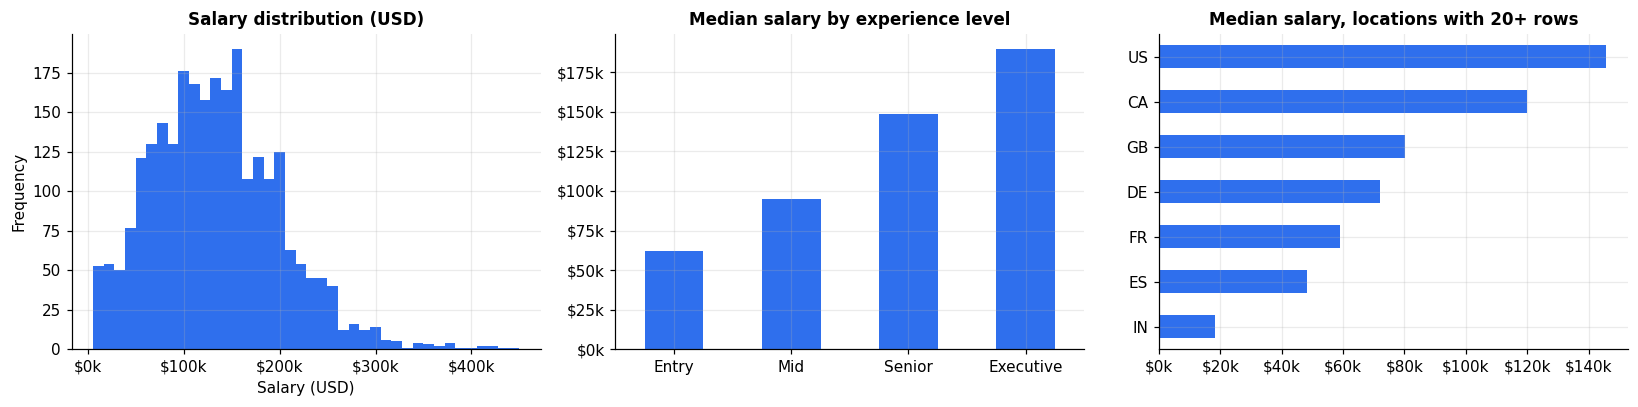

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
dedup[TARGET].plot.hist(bins=40, ax=ax[0], color=BLUE, title='Salary distribution (USD)')
dedup.groupby('experience_level')[TARGET].median().reindex(['EN', 'MI', 'SE', 'EX']).rename(index={'EN': 'Entry', 'MI': 'Mid', 'SE': 'Senior', 'EX': 'Executive'}).plot.bar(ax=ax[1], color=BLUE, title='Median salary by experience level', rot=0)
loc = dedup.groupby('company_location')[TARGET].agg(['median', 'count']).query('count >= 20')['median'].sort_values()
loc.plot.barh(ax=ax[2], color=BLUE, title='Median salary, locations with 20+ rows')
for a in ax: a.set_xlabel('')
ax[0].xaxis.set_major_formatter(kfmt); ax[1].yaxis.set_major_formatter(kfmt); ax[2].xaxis.set_major_formatter(kfmt); ax[2].set_ylabel('')
ax[0].set_xlabel('Salary (USD)')
plt.tight_layout()

Salaries are right-skewed, rise steeply with experience, and differ hugely by country. Three quarters of rows are US companies, so most other locations are thin.

## 2. Data cleaning log
What was changed, why, and what it cost or bought. Steps that learn from the data (rare-category sets, tail quantiles) are fit on training folds only.

In [4]:
n_title_rare = (dedup.job_title.value_counts() < 10).sum()
n_loc_rare = (dedup.company_location.value_counts() < 10).sum()
log = pd.DataFrame([
    ['Drop salary, salary_currency, employee_residence', 'Redundant with salary_in_usd and company_location', 'Not tested separately'],
    ['Remove exact duplicate rows', f'{len(raw) - len(dedup):,} rows ({1 - len(dedup)/len(raw):.0%}) appear more than once and leak across train/test', 'Scores get worse but honest'],
    ['Model log(salary), convert back to USD', 'Errors become proportional to salary instead of dominated by the highest earners', 'Mixed: see stage 2'],
    ['Collapse rare titles and locations (<10 rows)', f'{n_title_rare} of {dedup.job_title.nunique()} titles and {n_loc_rare} of {dedup.company_location.nunique()} locations too thin to learn from', 'Small'],
    ['Add job family, region, level ordinal', 'Groups 93 titles into 7 families and 72 locations into 6 regions', 'Small'],
    ['Trim the top and bottom 1% of salaries in training only', 'Extreme rows pull fits; held-out rows are never trimmed', 'Small'],
], columns=['Step', 'Why', 'Effect on held-out scores'])
log.style.hide(axis='index').set_properties(**{'text-align': 'left', 'white-space': 'normal'})

Step,Why,Effect on held-out scores
"Drop salary, salary_currency, employee_residence",Redundant with salary_in_usd and company_location,Not tested separately
Remove exact duplicate rows,"1,172 rows (31%) appear more than once and leak across train/test",Scores get worse but honest
"Model log(salary), convert back to USD",Errors become proportional to salary instead of dominated by the highest earners,Mixed: see stage 2
Collapse rare titles and locations (<10 rows),64 of 93 titles and 59 of 72 locations too thin to learn from,Small
"Add job family, region, level ordinal",Groups 93 titles into 7 families and 72 locations into 6 regions,Small
Trim the top and bottom 1% of salaries in training only,Extreme rows pull fits; held-out rows are never trimmed,Small


A note on trimming: dropping extreme salaries from the **test** rows too makes any model look much better (in a quick test RMSE fell by roughly $5k), but that is a different, easier question. Trimming is therefore applied to training rows only, and every score is measured on the original held-out rows.

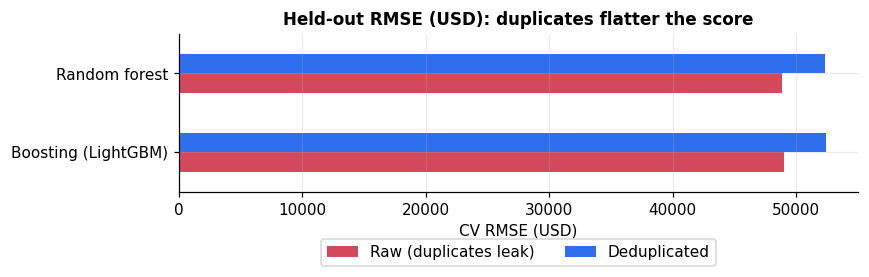

In [5]:
ax = stage[stage.stage.isin([0, 1])].pivot(index='family', columns='stage', values='rmse')
ax.columns = ['Raw (duplicates leak)', 'Deduplicated']
ax.rename(index={'RF': 'Random forest', 'LGBM': 'Boosting (LightGBM)'}).plot.barh(figsize=(8, 2.8), color=[RED, BLUE], title='Held-out RMSE (USD): duplicates flatter the score')
plt.xlabel('CV RMSE (USD)'); plt.ylabel(''); plt.legend(loc='upper center', bbox_to_anchor=(.5, -.25), ncol=2); plt.tight_layout()

## 3. From the first messy plot to the final one
Each panel is the **out-of-fold** prediction for every row (the model never saw that row) against the actual salary. The red dashed line is a perfect prediction; the orange line is the average prediction within deciles of actual salary, so the gap between orange and red shows how much the model shrinks toward the middle.

Stage 0 uses the raw, duplicated data (a different, leaky test set); stages 1-4 use the deduplicated rows. Stage 4 = tuned with nested cross-validation.

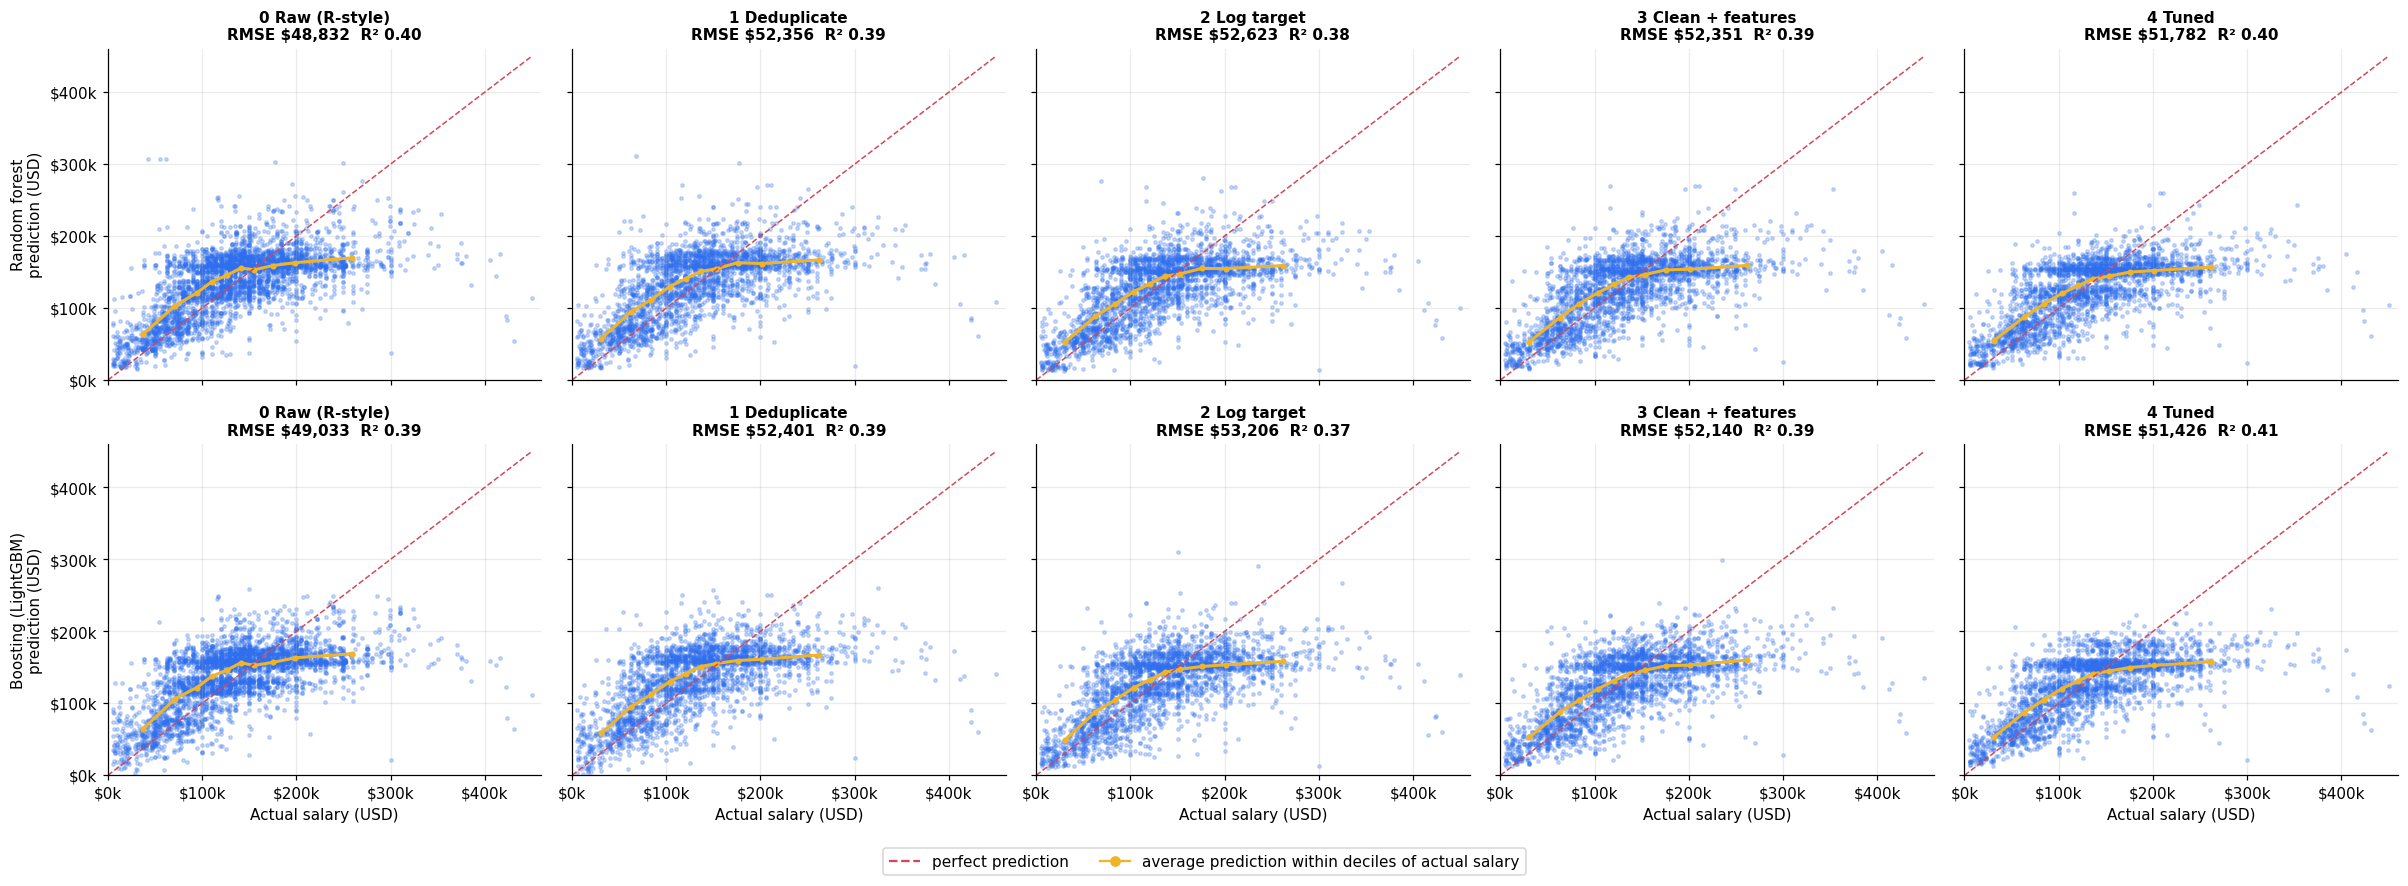

In [6]:
STAGES = ['0 Raw (R-style)', '1 Deduplicate', '2 Log target', '3 Clean + features', '4 Tuned']
fig, axes = plt.subplots(2, 5, figsize=(22, 8), sharex=True, sharey=True)
for r, (tag, title) in enumerate([('RF', 'Random forest'), ('LGBM', 'Boosting (LightGBM)')]):
    for sidx in range(5):
        a = axes[r, sidx]
        y = oof['y_raw'] if sidx == 0 else oof['y_dedup']
        p = oof[f'stage{sidx}_{tag}']
        a.scatter(y, p, s=5, alpha=.25, color=BLUE)
        edges = np.quantile(y, np.linspace(0, 1, 11)); idx = np.clip(np.digitize(y, edges[1:-1]), 0, 9)
        a.plot([y[idx == k].mean() for k in range(10)], [p[idx == k].mean() for k in range(10)], '-o', color=GOLD, ms=3, lw=2)
        a.plot([0, 450000], [0, 450000], '--', color=RED, lw=1)
        row = s.loc[(tag, sidx)]
        a.set_title(f'{STAGES[sidx]}\nRMSE {usd(row.rmse)}  R\u00b2 {row.r2:.2f}', fontsize=10)
        a.set_xlim(0, 460000); a.set_ylim(0, 460000); a.xaxis.set_major_formatter(kfmt); a.yaxis.set_major_formatter(kfmt)
        if r == 1: a.set_xlabel('Actual salary (USD)')
        if sidx == 0: a.set_ylabel(f'{title}\nprediction (USD)')
fig.legend(handles=[Line2D([0], [0], color=RED, ls='--', label='perfect prediction'), Line2D([0], [0], color=GOLD, marker='o', label='average prediction within deciles of actual salary')], loc='lower center', ncol=2, bbox_to_anchor=(.5, -.01))
plt.tight_layout(rect=(0, .04, 1, 1))

**How to read it.** The cloud tightens a little and the orange line moves toward the diagonal from stage to stage, but it never collapses onto it. Section 4 shows why that is a property of the data, and why the original R plots looked tighter.

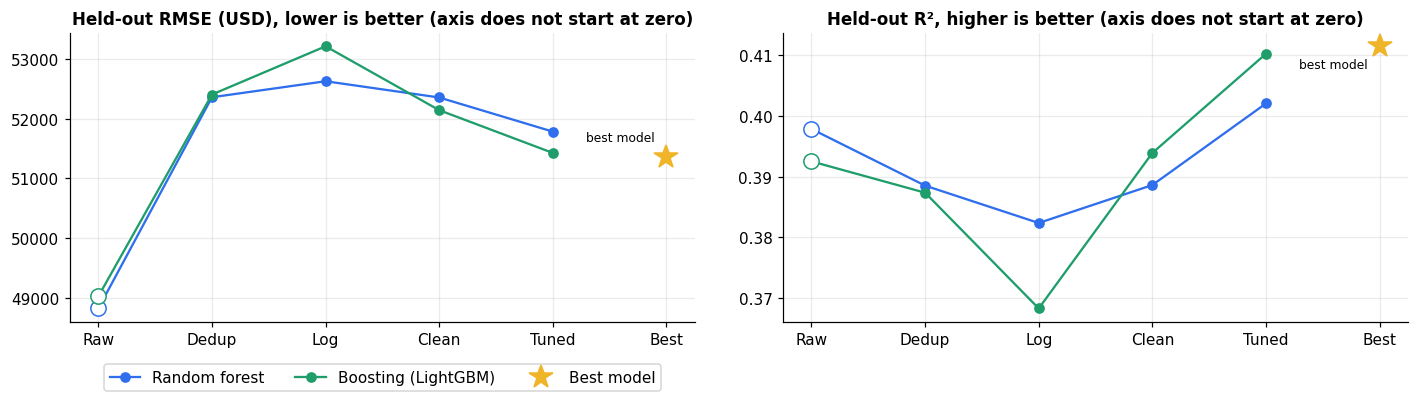

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for tag, name, col in (('RF', 'Random forest', BLUE), ('LGBM', 'Boosting (LightGBM)', GREEN)):
    d_ = stage[(stage.family == tag) & (stage.stage <= 4)]
    ax[0].plot(d_.stage, d_.rmse, '-o', color=col, label=name)
    ax[1].plot(d_.stage, d_.r2, '-o', color=col, label=name)
    ax[0].plot(0, d_.rmse.iloc[0], 'o', mfc='white', mec=col, ms=10)
    ax[1].plot(0, d_.r2.iloc[0], 'o', mfc='white', mec=col, ms=10)
b = stage[stage.stage == 5].iloc[0]
ax[0].plot(5, b.rmse, '*', color=GOLD, ms=16, label='Best model'); ax[1].plot(5, b.r2, '*', color=GOLD, ms=16)
for a, t in zip(ax, ['Held-out RMSE (USD), lower is better (axis does not start at zero)', 'Held-out R\u00b2, higher is better (axis does not start at zero)']):
    a.set_title(t); a.set_xticks(range(6)); a.set_xticklabels(['Raw', 'Dedup', 'Log', 'Clean', 'Tuned', 'Best'])
ax[0].annotate('best model', (5, b.rmse), textcoords='offset points', xytext=(-8, 10), ha='right', fontsize=8)
ax[1].annotate('best model', (5, b.r2), textcoords='offset points', xytext=(-8, -14), ha='right', fontsize=8)
ax[0].legend(loc='upper center', bbox_to_anchor=(.5, -.12), ncol=3); plt.tight_layout()

The hollow stage-0 markers are measured on a different, leaky test set, so they should not be compared with the others. Stage 1 is the honest starting line; every later gain is real but modest.

## 4. Why the R plots hugged the diagonal, and why these do not

**Training fit versus held-out fit.** The original R report plotted predictions on the training data. A flexible model can memorise the rows it trains on, so those plots look excellent. The panels below fit the same models on all rows and plot (left) predictions for rows the model has seen against (right) honest out-of-fold predictions.

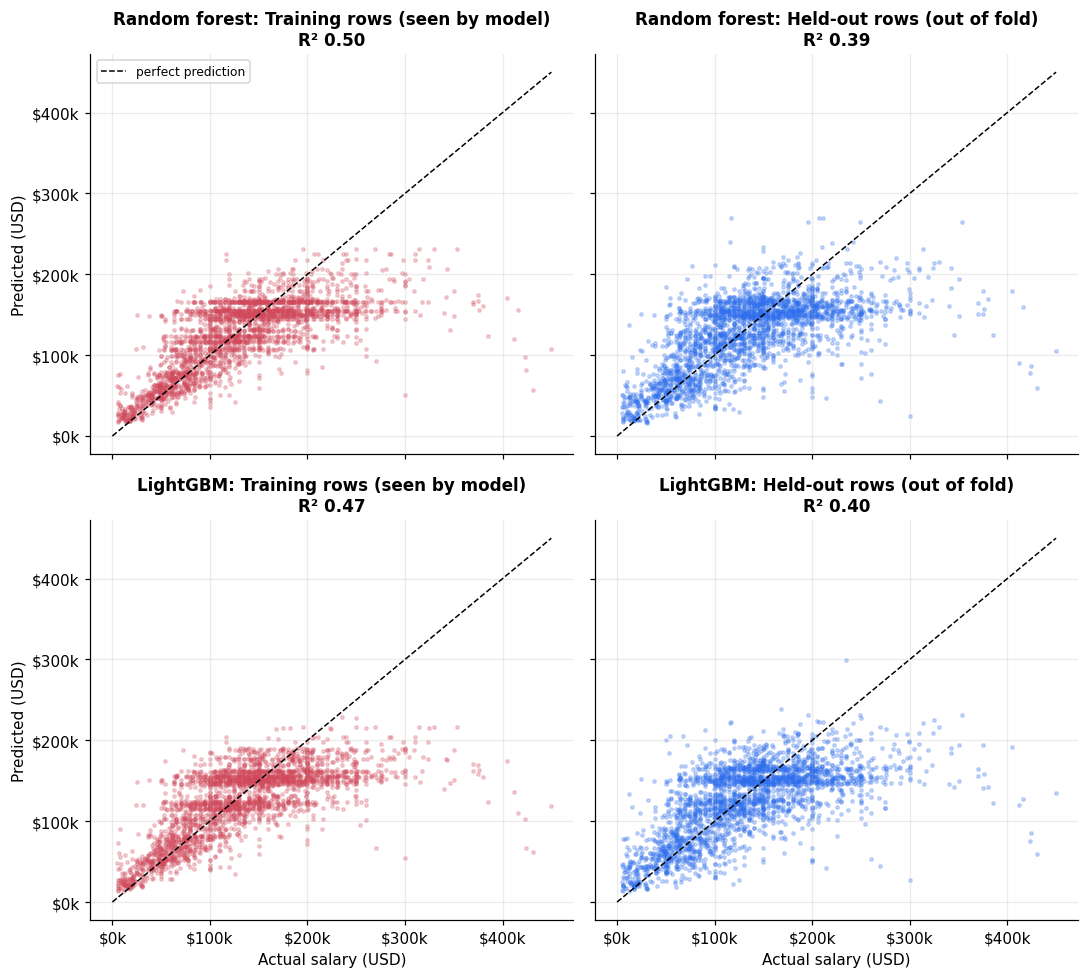

In [8]:
from sklearn.metrics import r2_score
fig, axes = plt.subplots(2, 2, figsize=(10, 9), sharex=True, sharey=True)
X, y = dedup.drop(columns=[TARGET]), dedup[TARGET].to_numpy()
for r, (tag, name, key) in enumerate([('RF', 'Random forest', 'Random forest'), ('LGBM', 'LightGBM', 'LightGBM')]):
    fitted = build(key, 'eng', True, True).fit(X, y)
    pin = fitted.predict(X); pout = oof[f'stage3_{tag}']
    for c, (p, lab) in enumerate([(pin, 'Training rows (seen by model)'), (pout, 'Held-out rows (out of fold)')]):
        a = axes[r, c]; a.scatter(y, p, s=5, alpha=.25, color=RED if c == 0 else BLUE)
        a.plot([0, 450000], [0, 450000], 'k--', lw=1, label='perfect prediction')
        a.xaxis.set_major_formatter(kfmt); a.yaxis.set_major_formatter(kfmt)
        if r == 0 and c == 0: a.legend(loc='upper left', fontsize=8)
        a.set_title(f'{name}: {lab}\nR\u00b2 {r2_score(y, p):.2f}')
        if r == 1: a.set_xlabel('Actual salary (USD)')
        if c == 0: a.set_ylabel('Predicted (USD)')
plt.tight_layout()

**Irreducible noise.** Take every group of people with an identical profile (same title, level, location, company size, employment type, year and remote ratio) and measure how far apart their salaries are. If a model could not tell them apart, this spread is the best it could ever explain.

People with the *same* profile typically differ by **30%** (std/mean). For the largest group above, the same title, level, location, size and year range from $65,000 to $310,000. A model that sees only these columns cannot do better than the group average, so held-out predictions will always fan out around the diagonal.

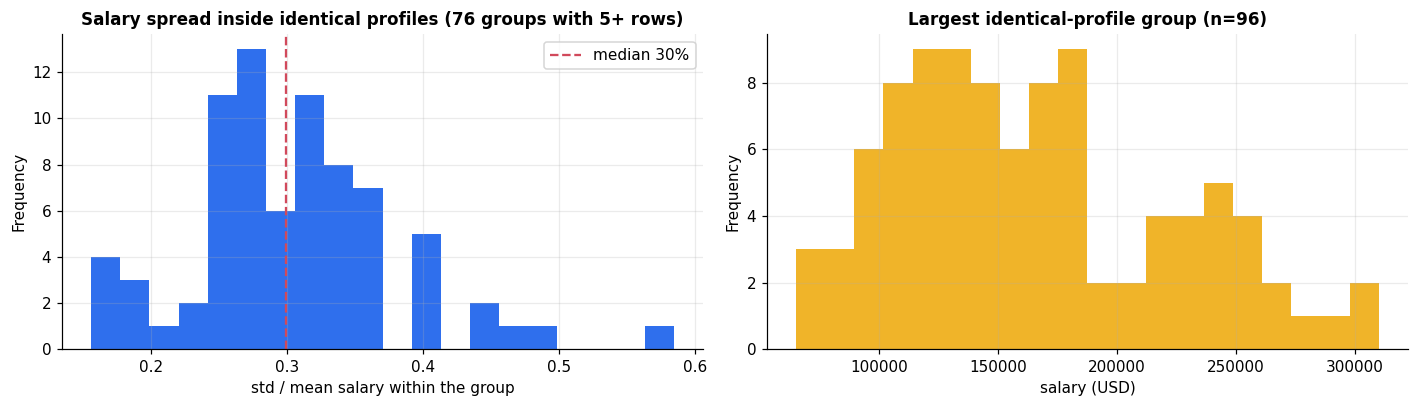

In [9]:
from features import CAT_RAW, NUM_RAW
g = dedup.groupby(CAT_RAW + NUM_RAW)[TARGET].agg(['count', 'std', 'mean']).query('count >= 5')
cv_ = (g['std'] / g['mean'])
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
cv_.plot.hist(bins=20, ax=ax[0], color=BLUE, title=f'Salary spread inside identical profiles ({len(g)} groups with 5+ rows)')
ax[0].axvline(cv_.median(), color=RED, ls='--', label=f'median {cv_.median():.0%}'); ax[0].legend(); ax[0].set_xlabel('std / mean salary within the group')
big = g.sort_values('count', ascending=False).head(1).index[0]
sub = dedup[(dedup[CAT_RAW + NUM_RAW] == pd.Series(big, index=CAT_RAW + NUM_RAW)).all(axis=1)][TARGET]
sub.plot.hist(bins=20, ax=ax[1], color=GOLD, title=f'Largest identical-profile group (n={len(sub)})'); ax[1].set_xlabel('salary (USD)')
plt.tight_layout()
display(Markdown(f'People with the *same* profile typically differ by **{cv_.median():.0%}** (std/mean). For the largest group above, the same title, level, location, size and year range from {usd(sub.min())} to {usd(sub.max())}. A model that sees only these columns cannot do better than the group average, so held-out predictions will always fan out around the diagonal.'))

**Why predictions form horizontal bands.** With only seven features there are a few hundred distinct profiles, so many rows receive nearly identical predictions. The bands in the scatter plots are those profile averages, not an artefact.

## 5. Model search
Everything below uses the same cleaned pipeline and the same 15 folds. Each model is shown at sensible defaults and tuned with nested cross-validation (the search never sees the outer test fold).

Candidates: **ridge** (linear), **KNN**, **random forest**, **extra trees**, then the boosting family: **HistGradientBoosting**, **XGBoost**, **LightGBM**, **CatBoost** (built for categorical features), a small **neural net (MLP)**, and a **stacking** blend of ridge, random forest and LightGBM. TabPFN was not tested: it needs a pretrained weights download, so the scikit-learn MLP stands in as the neural option.

> **Note: CatBoost was evaluated at its default settings only.** Its nested tuning run was stopped after about 5 minutes because it needed roughly 25 more (it is the slowest model here), so there is no "tuned" CatBoost point below. Its default is already tied with the best model, so tuning is unlikely to change the conclusion, but a tuned CatBoost remains untested.

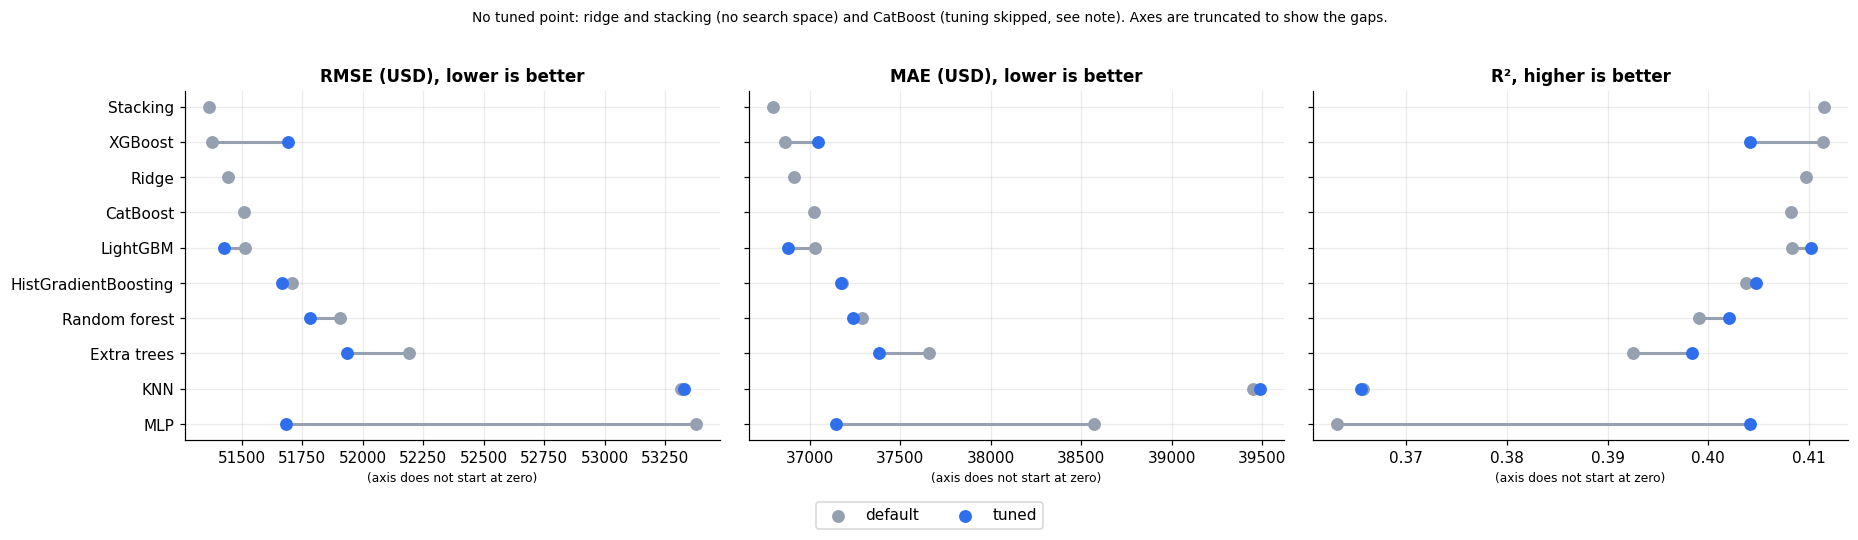

In [10]:
s2 = search[search.model != 'Median baseline'].copy()
s2['kind'] = np.where(s2.tuned, 'tuned', 'default')
piv = s2.pivot(index='model', columns='kind', values='rmse')
order = s2[~s2.tuned].set_index('model').rmse.sort_values().index
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for k, (col, title) in enumerate([('rmse', 'RMSE (USD), lower is better'), ('mae', 'MAE (USD), lower is better'), ('r2', 'R\u00b2, higher is better')]):
    pv = s2.pivot(index='model', columns='kind', values=col).reindex(order)
    y = np.arange(len(pv))
    ax[k].hlines(y, pv.min(axis=1), pv.max(axis=1), color=GREY, lw=2)
    ax[k].scatter(pv['default'], y, color=GREY, s=55, label='default', zorder=3)
    ax[k].scatter(pv['tuned'], y, color=BLUE, s=55, label='tuned', zorder=3)
    ax[k].set_yticks(y); ax[k].set_yticklabels(pv.index if k == 0 else []); ax[k].invert_yaxis(); ax[k].set_title(title)
h, l = ax[0].get_legend_handles_labels(); fig.legend(h, l, loc='lower center', ncol=2, bbox_to_anchor=(.5, -.02))
plt.suptitle('No tuned point: ridge and stacking (no search space) and CatBoost (tuning skipped, see note). Axes are truncated to show the gaps.', y=1.02, fontsize=9)
for a_ in ax: a_.set_xlabel('(axis does not start at zero)', fontsize=8)
plt.tight_layout(rect=(0, .05, 1, 1))

Tuning moves each model by a few hundred dollars at most, and several tuned models score *worse* than their defaults on held-out folds, a sign that the search is fitting noise rather than signal. The whole top of the table sits within about $1,000 of each other.

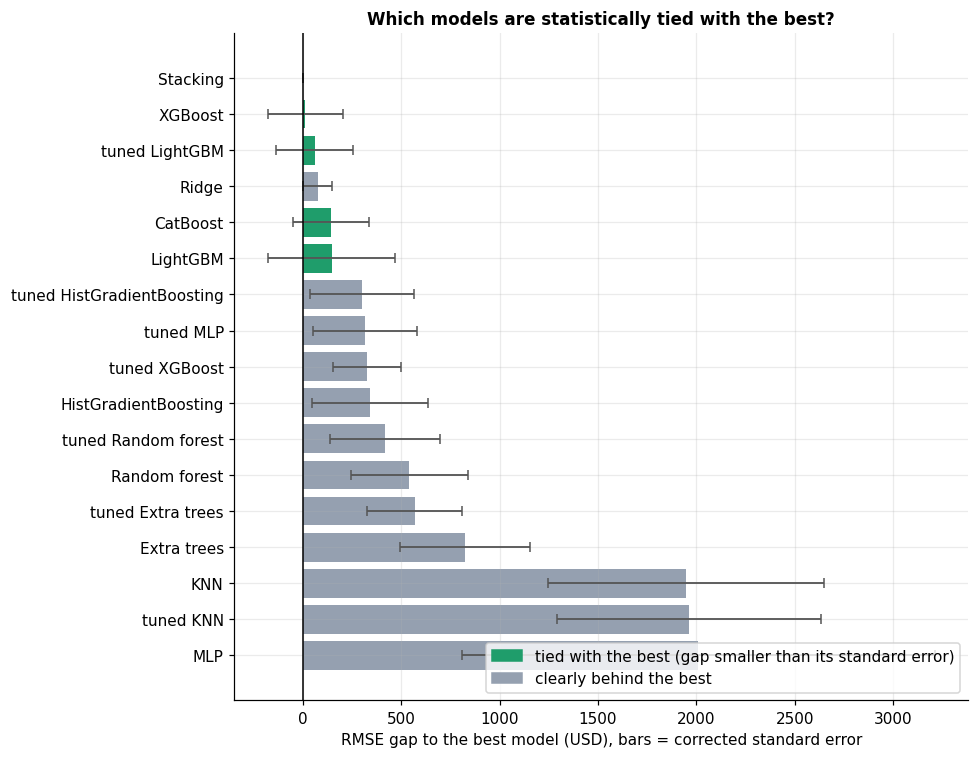

In [11]:
base = search.set_index('key')
rows = base[base.model != 'Median baseline'].sort_values('rmse')
fig, ax = plt.subplots(figsize=(9, 7))
y = np.arange(len(rows))
colors = np.where(rows.tied, GREEN, GREY)
ax.barh(y, rows.gap_to_best, xerr=rows.gap_se, color=colors, ecolor='#555', error_kw={'lw': 1.2, 'capsize': 3})
ax.set_yticks(y); ax.set_yticklabels([('tuned ' if t else '') + m for m, t in zip(rows.model, rows.tuned)]); ax.invert_yaxis()
ax.set_xlabel('RMSE gap to the best model (USD), bars = corrected standard error'); ax.set_title('Which models are statistically tied with the best?')
ax.axvline(0, color='k', lw=1)
ax.legend(handles=[Patch(color=GREEN, label='tied with the best (gap smaller than its standard error)'), Patch(color=GREY, label='clearly behind the best')], loc='lower right')
plt.tight_layout()

## 6. The decision rule (fixed in advance)
1. The **accuracy winner** is the model with the lowest mean held-out RMSE.
2. Any model whose paired fold-by-fold gap to the winner is smaller than its (corrected resampled) standard error is **tied**: the data cannot separate them.
3. Among tied models, prefer **the simplest** (a linear model beats a boosted ensemble when accuracy is equal).
4. For the *product* (the web app), pick the simplest tied model that can output a calibrated 10-90% range natively.

In [12]:
def nm(key): return ('tuned ' if key.startswith('tuned_') else '') + key.split('_', 1)[1]
tied = base[base.tied]
display(Markdown(f'''| Role | Model | Why |
|---|---|---|
| **Accuracy winner** | **{nm(decision['accuracy_winner'])}** | lowest mean RMSE ({usd(base.loc[decision['accuracy_winner'], 'rmse'])}) |
| **Parsimonious pick** | **{nm(decision['parsimonious_pick'])}** | simplest of the {decision['n_tied']} models tied with the winner |
| **Product pick** | **{nm(decision['product_pick'])}** | simplest tied model with native 10-90% quantile output |
'''))
cols = ['model', 'tuned', 'rmse', 'mae', 'r2', 'gap_to_best', 'gap_se', 'tied', 'interval_capable', 'seconds']
(search.sort_values('rmse')[cols].round({'rmse': 0, 'mae': 0, 'r2': 3, 'gap_to_best': 0, 'gap_se': 0, 'seconds': 0})
 .style.hide(axis='index').background_gradient(subset=['rmse'], cmap='Blues_r').format({'rmse': '{:,.0f}', 'mae': '{:,.0f}', 'gap_to_best': '{:,.0f}', 'gap_se': '{:,.0f}'}))

| Role | Model | Why |
|---|---|---|
| **Accuracy winner** | **Stacking** | lowest mean RMSE ($51,366) |
| **Parsimonious pick** | **XGBoost** | simplest of the 5 models tied with the winner |
| **Product pick** | **XGBoost** | simplest tied model with native 10-90% quantile output |


model,tuned,rmse,mae,r2,gap_to_best,gap_se,tied,interval_capable,seconds
Stacking,False,"51,366","36,798",0.411000,0,0,True,False,31.000000
XGBoost,False,"51,379","36,864",0.411000,12,191,True,True,1.000000
LightGBM,True,"51,426","36,879",0.410000,60,195,True,True,23.000000
Ridge,False,"51,442","36,914",0.410000,75,75,False,False,0.000000
CatBoost,False,"51,510","37,022",0.408000,144,195,True,True,59.000000
LightGBM,False,"51,512","37,031",0.408000,146,322,True,True,0.000000
HistGradientBoosting,True,"51,666","37,171",0.405000,300,264,False,True,49.000000
MLP,True,"51,683","37,142",0.404000,317,264,False,False,65.000000
XGBoost,True,"51,691","37,044",0.404000,324,173,False,True,16.000000
HistGradientBoosting,False,"51,708","37,178",0.404000,342,294,False,True,1.000000


model,coverage,median_width,pinball
LightGBM,76.9%,"115,402","8,555"
HistGradientBoosting,76.5%,"115,693","8,605"
XGBoost,77.6%,"118,012","8,614"
CatBoost,76.6%,"117,615","8,655"


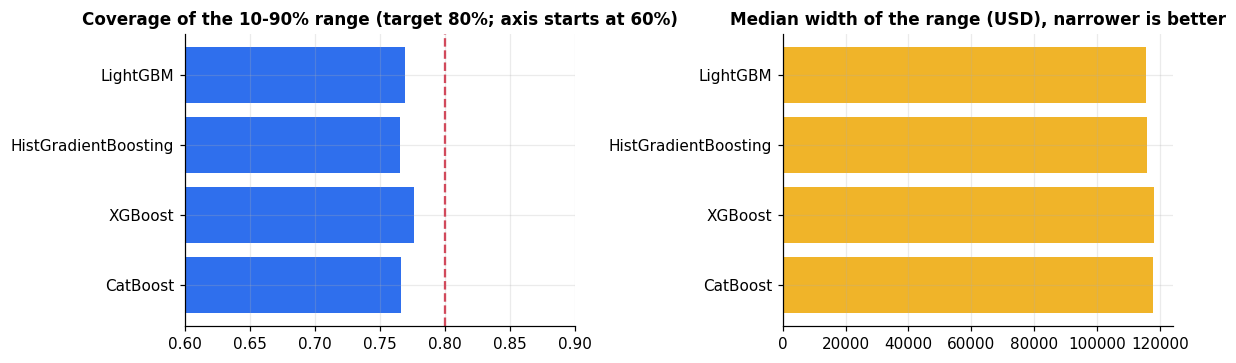

In [13]:
ic = pd.read_csv(f'{OUT}/interval_compare.csv')
display(ic.round({'coverage': 3, 'median_width': 0, 'pinball': 0}).style.hide(axis='index').format({'coverage': '{:.1%}', 'median_width': '{:,.0f}', 'pinball': '{:,.0f}'}))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].barh(ic.model, ic.coverage, color=BLUE); ax[0].axvline(.8, color=RED, ls='--'); ax[0].set_title('Coverage of the 10-90% range (target 80%; axis starts at 60%)'); ax[0].set_xlim(.6, .9)
ax[1].barh(ic.model, ic.median_width, color=GOLD); ax[1].set_title('Median width of the range (USD), narrower is better')
for a in ax: a.invert_yaxis()
plt.tight_layout()

In [14]:
rd = base.loc['search_Ridge']
ic_best = ic.sort_values('pinball').iloc[0]
app_row = ic[ic.model == 'LightGBM'].iloc[0]
top_span = rows[rows.tied].rmse.max() - rows.rmse.min()
display(Markdown(f'''### Decision
- **No model is clearly better than the others.** {decision['n_tied']} of {len(search)} configurations are statistically tied with the best, spanning only {usd(top_span)} of RMSE ({top_span / rows.rmse.min():.1%}).
- **Accuracy:** the lowest error belongs to **{nm(decision['accuracy_winner'])}**, but a stacked ensemble of three models costs 30 s versus under 1 s for the alternatives and gains {usd(base.loc[decision['parsimonious_pick'], 'gap_to_best'])} over the simplest tied model, **{nm(decision['parsimonious_pick'])}**. By the rule, that is the pick.
- **A near-tie worth knowing about:** plain **ridge regression** misses the cutoff by under a dollar (gap {usd(rd.gap_to_best)} vs standard error {usd(rd.gap_se)}), so by the strict rule it is not tied. In practice it is indistinguishable ({rd.gap_to_best / base.loc[decision['accuracy_winner'], 'rmse']:.2%} behind the best), is far simpler, and is the most interpretable model. If explanations matter more than the last $75, ridge is the better choice; section 8's premium analysis uses a linear model of the same kind.
- **Product (a *range*, not one number):** the rule's pick is **{nm(decision['product_pick'])}**. On the 10-90% range, however, **{ic_best.model}** has the lowest pinball loss ({usd(ic_best.pinball)}) and the web app already uses LightGBM quantile models (coverage {app_row.coverage:.1%}, median width {usd(app_row.median_width)}). The models differ by under 1% on pinball loss, so we **keep LightGBM in the app as a deliberate exception to the rule**: the rule did not score interval quality, and the app's intervals were validated separately.
- **More modelling effort will not help; more information will.** Adding features (skills, industry, tenure, company name) is the only lever left.
'''))

### Decision
- **No model is clearly better than the others.** 5 of 18 configurations are statistically tied with the best, spanning only $146 of RMSE (0.3%).
- **Accuracy:** the lowest error belongs to **Stacking**, but a stacked ensemble of three models costs 30 s versus under 1 s for the alternatives and gains $12 over the simplest tied model, **XGBoost**. By the rule, that is the pick.
- **A near-tie worth knowing about:** plain **ridge regression** misses the cutoff by under a dollar (gap $75 vs standard error $75), so by the strict rule it is not tied. In practice it is indistinguishable (0.15% behind the best), is far simpler, and is the most interpretable model. If explanations matter more than the last $75, ridge is the better choice; section 8's premium analysis uses a linear model of the same kind.
- **Product (a *range*, not one number):** the rule's pick is **XGBoost**. On the 10-90% range, however, **LightGBM** has the lowest pinball loss ($8,555) and the web app already uses LightGBM quantile models (coverage 76.9%, median width $115,402). The models differ by under 1% on pinball loss, so we **keep LightGBM in the app as a deliberate exception to the rule**: the rule did not score interval quality, and the app's intervals were validated separately.
- **More modelling effort will not help; more information will.** Adding features (skills, industry, tenure, company name) is the only lever left.


## 7. The chosen model in detail

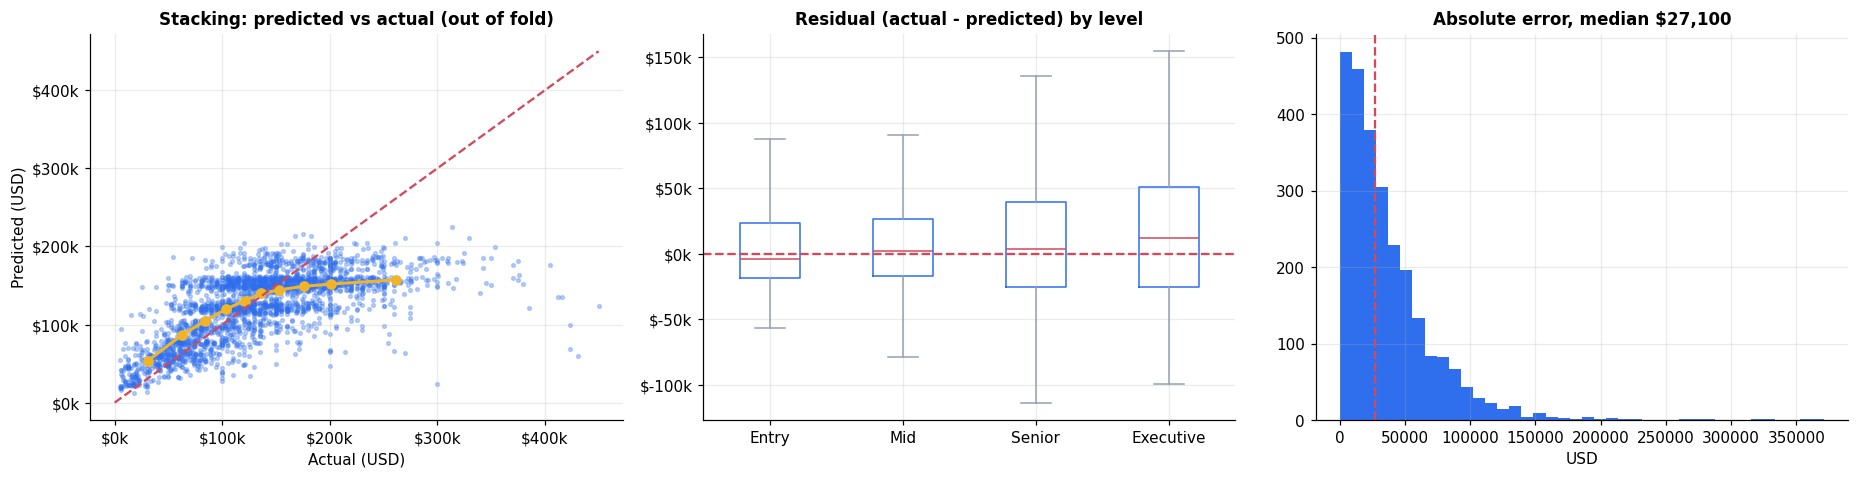

In [15]:
key = decision['accuracy_winner']
p = oof[key]; y = oof['y_dedup']
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
ax[0].scatter(y, p, s=6, alpha=.3, color=BLUE)
edges = np.quantile(y, np.linspace(0, 1, 11)); idx = np.clip(np.digitize(y, edges[1:-1]), 0, 9)
ax[0].plot([y[idx == k].mean() for k in range(10)], [p[idx == k].mean() for k in range(10)], '-o', color=GOLD, lw=2)
ax[0].plot([0, 450000], [0, 450000], '--', color=RED); ax[0].set_title(f'{nm(key)}: predicted vs actual (out of fold)'); ax[0].set_xlabel('Actual (USD)'); ax[0].set_ylabel('Predicted (USD)'); ax[0].xaxis.set_major_formatter(kfmt); ax[0].yaxis.set_major_formatter(kfmt)
res = y - p
lvl = pd.Categorical(dedup.experience_level.map({'EN': 'Entry', 'MI': 'Mid', 'SE': 'Senior', 'EX': 'Executive'}), categories=['Entry', 'Mid', 'Senior', 'Executive'], ordered=True)
pd.DataFrame({'level': lvl, 'residual': res}).boxplot(by='level', column='residual', ax=ax[1], showfliers=False, boxprops=dict(color=BLUE), medianprops=dict(color=RED), whiskerprops=dict(color=GREY), capprops=dict(color=GREY)); ax[1].axhline(0, color=RED, ls='--'); ax[1].yaxis.set_major_formatter(kfmt)
ax[1].set_title('Residual (actual - predicted) by level'); ax[1].set_xlabel(''); plt.suptitle('')
ax[2].hist(np.abs(res), bins=40, color=BLUE); ax[2].axvline(np.median(np.abs(res)), color=RED, ls='--')
ax[2].set_title(f'Absolute error, median {usd(np.median(np.abs(res)))}'); ax[2].set_xlabel('USD')
plt.tight_layout()

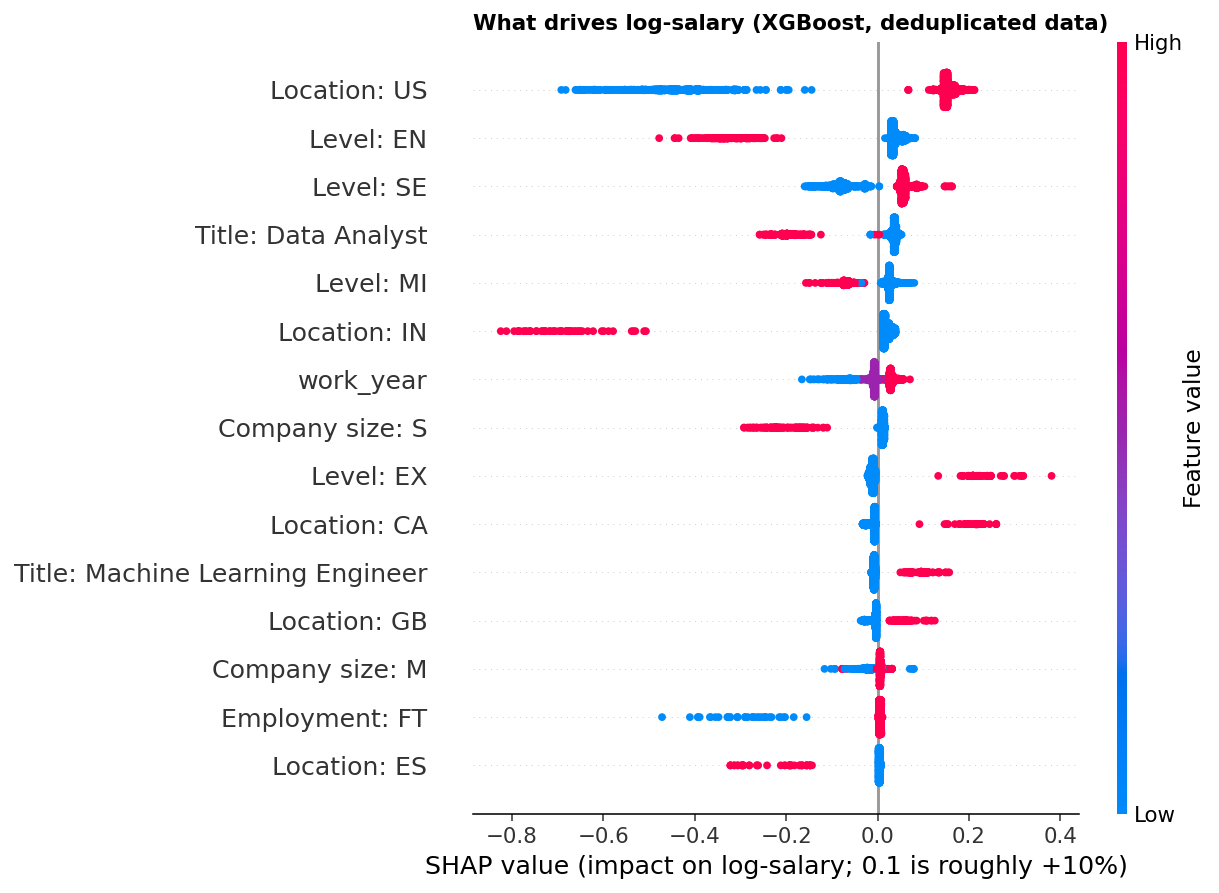

In [16]:
from IPython.display import Image
Image('outputs/shap_summary.png', width=620)

A US company location is the largest single effect; entry level pulls salary down, senior and executive levels push it up. These are associations in a survey sample, not causes.

The 10-90% quantile range covers **77.5%** of held-out salaries (target 80%).

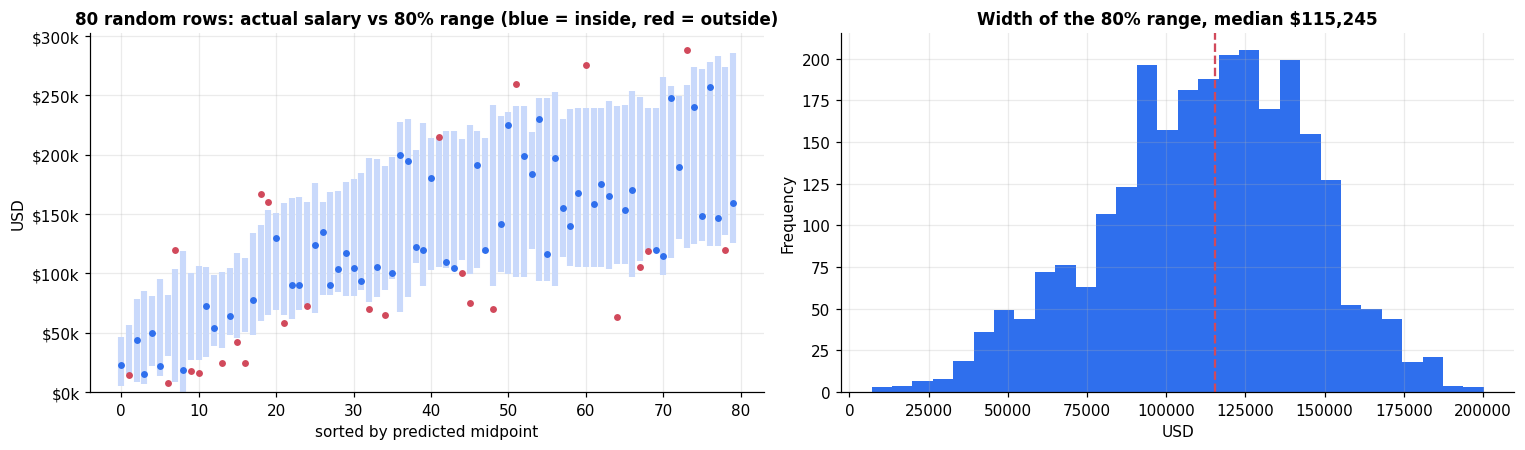

In [17]:
import numpy as np
from tune_models import oof_intervals
lo, hi = oof_intervals(dedup)
lo = np.clip(lo, 0, None)  # a salary cannot be negative
yv = dedup[TARGET].to_numpy(); inside = (yv >= lo) & (yv <= hi)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
idx = np.random.default_rng(1).choice(len(yv), 80, replace=False); idx = idx[np.argsort(((lo + hi) / 2)[idx])]
for j, i in enumerate(idx):
    ax[0].vlines(j, lo[i], hi[i], color='#c9d9fb', lw=4); ax[0].plot(j, yv[i], '.', color=BLUE if inside[i] else RED, ms=7)
ax[0].set_title('80 random rows: actual salary vs 80% range (blue = inside, red = outside)'); ax[0].set_ylim(0, None); ax[0].yaxis.set_major_formatter(kfmt); ax[0].set_xlabel('sorted by predicted midpoint'); ax[0].set_ylabel('USD')
pd.Series(hi - lo).plot.hist(bins=30, ax=ax[1], color=BLUE); ax[1].axvline(np.median(hi - lo), color=RED, ls='--')
ax[1].set_title(f'Width of the 80% range, median {usd(np.median(hi - lo))}'); ax[1].set_xlabel('USD')
plt.tight_layout()
display(Markdown(f'The 10-90% quantile range covers **{inside.mean():.1%}** of held-out salaries (target 80%).'))

## 8. What the business can do with this

Raw prediction accuracy is modest (R\u00b2 about 0.4), so the value is not in quoting one salary. It is in **benchmarking**: knowing the typical range for a role, how big each factor is, and where the data is too thin to trust.

### 8.1 How much does each factor move pay?
Each bar is the percentage difference in salary, holding the other factors constant, from a log-salary linear model with 300 bootstrap resamples (90% interval). Grey bars cross zero: no reliable effect.

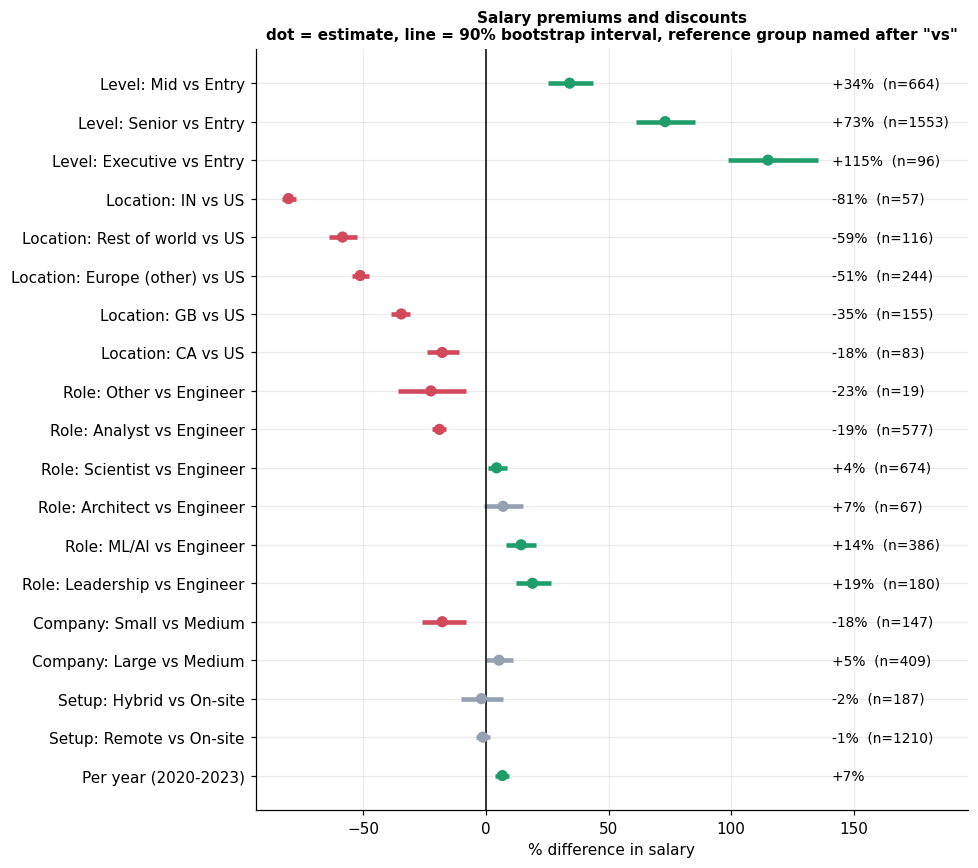

In [18]:
pr = pd.DataFrame(ins['premiums'])
pr['group'] = pd.Categorical(pr.factor.str.split(':').str[0], categories=['Level', 'Location', 'Role', 'Company', 'Setup', 'Per year (2020-2023)'], ordered=True)
pr = pr.sort_values(['group', 'pct'])
fig, ax = plt.subplots(figsize=(9, 8))
y = np.arange(len(pr))
col = np.where(~pr.significant, GREY, np.where(pr.pct > 0, GREEN, RED))
ax.hlines(y, pr.lo, pr.hi, color=col, lw=3); ax.scatter(pr.pct, y, color=col, zorder=3, s=40)
ax.axvline(0, color='k', lw=1)
ax.set_yticks(y); ax.set_yticklabels(pr.factor); ax.invert_yaxis()
for yi, (v, n_, f_) in enumerate(zip(pr.pct, pr.n, pr.factor)): ax.text(max(pr.hi) * 1.04, yi, f'{v:+.0f}%' + ('' if 'Per year' in f_ else f'  (n={n_})'), va='center', fontsize=9)
ax.set_xlim(None, max(pr.hi) * 1.45); ax.set_xlabel('% difference in salary'); ax.set_title('Salary premiums and discounts\ndot = estimate, line = 90% bootstrap interval, reference group named after "vs"', fontsize=10)
plt.tight_layout()
P = {r['factor']: r for r in ins['premiums']}

In [19]:
display(Markdown(f'''**Reading the chart**
- **Location is the dominant lever.** Compared with a US company, the same role pays about {abs(P['Location: GB vs US']['pct']):.0f}% less in the UK, {abs(P['Location: Europe (other) vs US']['pct']):.0f}% less elsewhere in Europe and {abs(P['Location: IN vs US']['pct']):.0f}% less in India.
- **Seniority compounds:** mid {P['Level: Mid vs Entry']['pct']:+.0f}%, senior {P['Level: Senior vs Entry']['pct']:+.0f}%, executive {P['Level: Executive vs Entry']['pct']:+.0f}% versus entry level.
- **Role matters less than level or location:** analysts earn {abs(P['Role: Analyst vs Engineer']['pct']):.0f}% less than engineers; ML/AI roles {P['Role: ML/AI vs Engineer']['pct']:+.0f}% and leadership {P['Role: Leadership vs Engineer']['pct']:+.0f}%.
- **Remote work shows no pay penalty or premium** (fully remote {P['Setup: Remote vs On-site']['pct']:+.0f}%, interval spans zero): remote is not a cost lever on salary alone.
- **Small companies pay {abs(P['Company: Small vs Medium']['pct']):.0f}% less** than medium ones; large companies are not reliably different.
- **Market drift:** about {P['Per year (2020-2023)']['pct']:+.0f}% per year across 2020-2023.
'''))

**Reading the chart**
- **Location is the dominant lever.** Compared with a US company, the same role pays about 35% less in the UK, 51% less elsewhere in Europe and 81% less in India.
- **Seniority compounds:** mid +34%, senior +73%, executive +115% versus entry level.
- **Role matters less than level or location:** analysts earn 19% less than engineers; ML/AI roles +14% and leadership +19%.
- **Remote work shows no pay penalty or premium** (fully remote -1%, interval spans zero): remote is not a cost lever on salary alone.
- **Small companies pay 18% less** than medium ones; large companies are not reliably different.
- **Market drift:** about +7% per year across 2020-2023.


### 8.2 Pay bands by role, level and market
Median salary in thousands of USD where at least 10 people are in the cell. Use the band (25th-75th percentile) in the table below, not the single median, when setting or checking a salary.

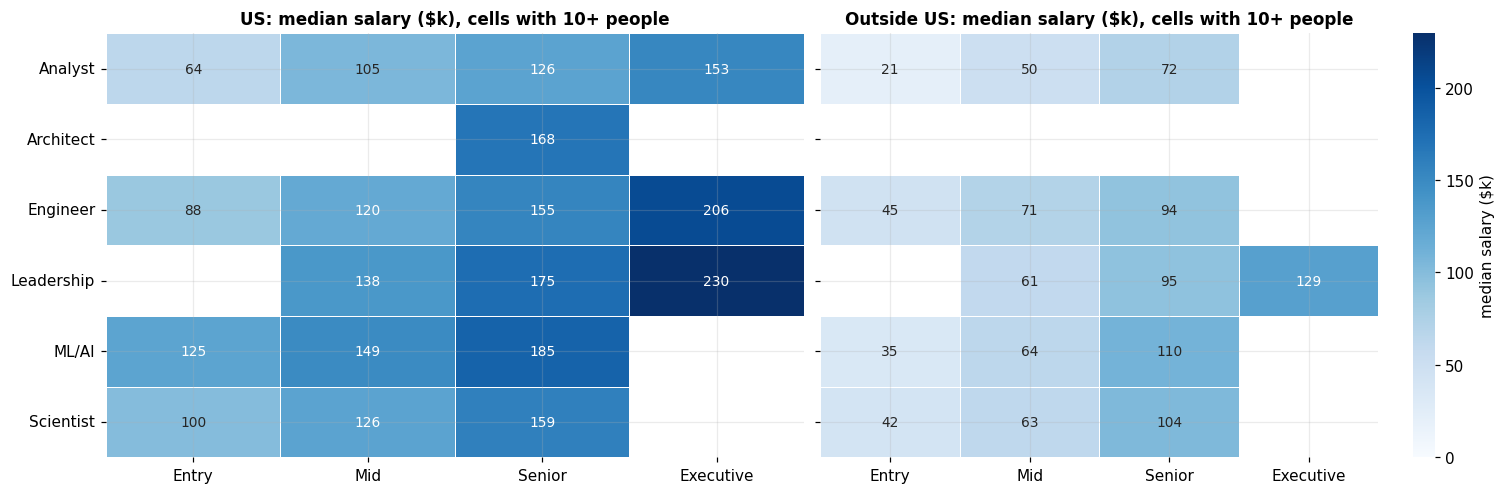

In [20]:
bd = pd.DataFrame(ins['bands'])
levels = ['Entry', 'Mid', 'Senior', 'Executive']
fams = sorted(bd.family.unique())  # same rows in both panels, so shared labels stay correct
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
vmax = bd['median'].max() / 1000
for a, mk in zip(ax, ['US', 'Outside US']):
    t = bd[bd.market == mk].pivot(index='family', columns='level', values='median').reindex(index=fams, columns=levels) / 1000
    sns.heatmap(t, annot=True, fmt='.0f', cmap='Blues', vmin=0, vmax=vmax, cbar=mk != 'US', linewidths=.5, ax=a, annot_kws={'size': 9},
                cbar_kws={'label': 'median salary ($k)'} if mk != 'US' else None)
    a.set_title(f'{mk}: median salary ($k), cells with 10+ people'); a.set_xlabel(''); a.set_ylabel('')
plt.tight_layout()

In [21]:
tab = bd[(bd.market == 'US') & (bd.n >= 30)].sort_values('median', ascending=False)
tab = tab.assign(band=lambda t: t.p25.map(usd) + ' to ' + t.p75.map(usd), median_=lambda t: t['median'].map(usd))
tab[['family', 'level', 'n', 'median_', 'band']].rename(columns={'family': 'Role family', 'level': 'Level', 'n': 'People', 'median_': 'Median', 'band': 'Middle 50% band'}).style.hide(axis='index')

Role family,Level,People,Median,Middle 50% band
Engineer,Executive,36,"$206,000","$163,350 to $239,750"
ML/AI,Senior,153,"$184,590","$145,000 to $214,000"
Leadership,Senior,83,"$175,000","$140,050 to $202,250"
Architect,Senior,54,"$168,250","$125,750 to $209,694"
Scientist,Senior,362,"$159,150","$134,077 to $200,000"
Engineer,Senior,384,"$155,000","$122,450 to $194,250"
ML/AI,Mid,64,"$149,250","$118,075 to $183,475"
Scientist,Mid,84,"$126,250","$100,000 to $151,508"
Analyst,Senior,289,"$125,600","$104,300 to $156,400"
Engineer,Mid,95,"$120,000","$97,050 to $153,500"


### 8.3 Where can this be trusted?
Coverage is how often the real salary fell inside the model's 80% range, out of fold. A segment near 80% is well calibrated; the number of people (n) shows how much data stands behind it.

**Least well calibrated segments (30+ people):** Location: Rest of world 70% (n=116), Location: IN 74% (n=57), Role: ML/AI 74% (n=386), Location: CA 75% (n=83), Level: Entry 75% (n=270). The model undercovers where data is thin or pay is unusually low or high.

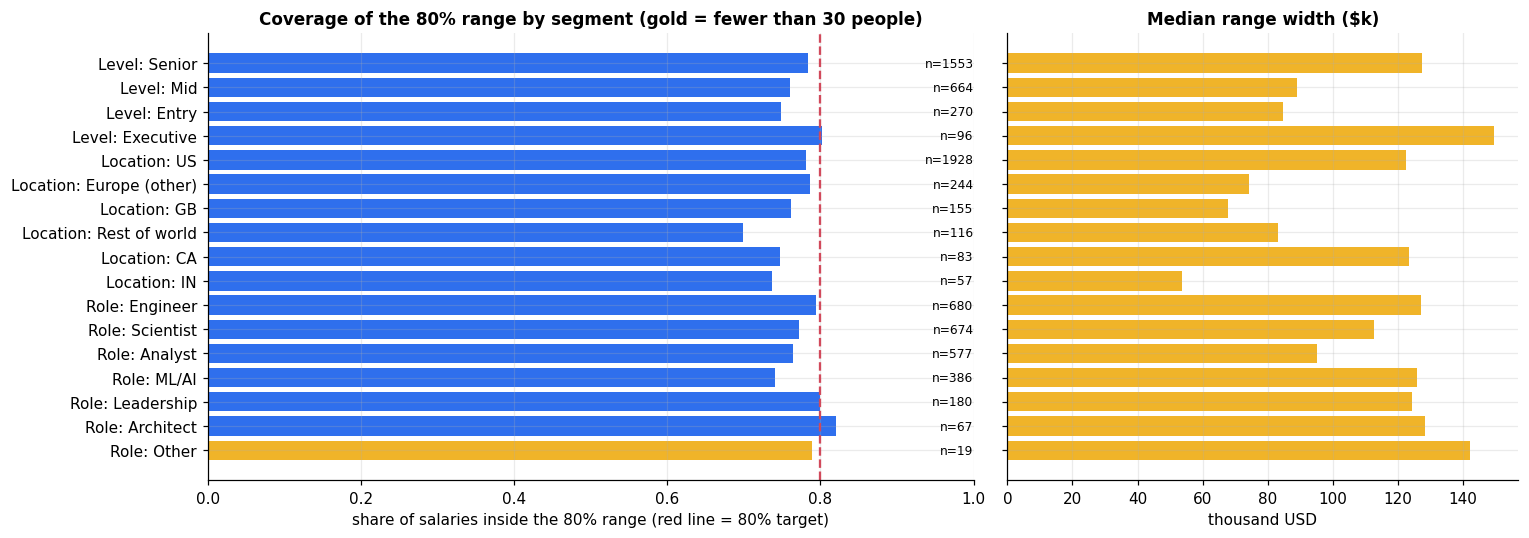

In [22]:
rl = pd.DataFrame(ins['reliability'])
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [3, 2]})
r_ = rl[rl.group != 'All'].copy(); r_['label'] = r_.group + ': ' + r_.segment
r_ = r_.sort_values(['group', 'n'], ascending=[True, False])
ax[0].barh(r_.label, r_.coverage, color=np.where(r_.n < 30, GOLD, BLUE)); ax[0].axvline(.8, color=RED, ls='--')
for yi, (c, n_) in enumerate(zip(r_.coverage, r_.n)): ax[0].text(1.0, yi, f'n={n_}', va='center', ha='right', fontsize=8)
ax[0].set_xlim(0, 1.0); ax[0].invert_yaxis(); ax[0].set_xlabel('share of salaries inside the 80% range (red line = 80% target)'); ax[0].set_title('Coverage of the 80% range by segment (gold = fewer than 30 people)')
ax[1].barh(r_.label, r_.median_width / 1000, color=GOLD); ax[1].invert_yaxis(); ax[1].set_yticklabels([]); ax[1].set_title('Median range width ($k)'); ax[1].set_xlabel('thousand USD')
plt.tight_layout()
weak = r_[(r_.coverage < .76) & (r_.n >= 30)].sort_values('coverage')
display(Markdown('**Least well calibrated segments (30+ people):** ' + (', '.join(f'{a} {c:.0%} (n={n_})' for a, c, n_ in zip(weak.label, weak.coverage, weak.n)) or 'none') + '. The model undercovers where data is thin or pay is unusually low or high.'))

In [23]:
W = [r for r in ins['reliability'] if r['group'] == 'All'][0]['median_width']
display(Markdown(f'''### 8.4 Decisions this supports

| Business question | How to use the analysis | Confidence |
|---|---|---|
| **Set or review a pay band** for a role | Start from the 25-75% band for the role family, level and market (8.2); adjust for company size (about {P['Company: Small vs Medium']['pct']:.0f}% for small firms) | High where n is large (US engineers, scientists, analysts) |
| **Check an offer** | Enter the profile in the web app; treat the 10-90% range as plausible and an offer below it as a retention or fairness flag | Medium: ranges are wide (median {usd(W)}) |
| **Where to hire** | Location is the biggest cost driver (8.1). The data supports quantifying the gap, not judging output or quality | High for UK, Europe, India; low for thin locations |
| **Remote policy** | Remote work shows no reliable salary penalty or premium ({P['Setup: Remote vs On-site']['pct']:+.0f}%), so going remote does not by itself change what you must pay | Medium: remote is a self-reported field |
| **Career-ladder budgeting** | Plan for about {P['Level: Mid vs Entry']['pct']:+.0f}% (entry to mid) and {P['Level: Senior vs Entry']['pct']:+.0f}% (entry to senior) | High |
| **Forecasting wage inflation** | About {P['Per year (2020-2023)']['pct']:+.0f}% a year in this sample | Low: four years, survey sample |
'''))

### 8.4 Decisions this supports

| Business question | How to use the analysis | Confidence |
|---|---|---|
| **Set or review a pay band** for a role | Start from the 25-75% band for the role family, level and market (8.2); adjust for company size (about -18% for small firms) | High where n is large (US engineers, scientists, analysts) |
| **Check an offer** | Enter the profile in the web app; treat the 10-90% range as plausible and an offer below it as a retention or fairness flag | Medium: ranges are wide (median $115,245) |
| **Where to hire** | Location is the biggest cost driver (8.1). The data supports quantifying the gap, not judging output or quality | High for UK, Europe, India; low for thin locations |
| **Remote policy** | Remote work shows no reliable salary penalty or premium (-1%), so going remote does not by itself change what you must pay | Medium: remote is a self-reported field |
| **Career-ladder budgeting** | Plan for about +34% (entry to mid) and +73% (entry to senior) | High |
| **Forecasting wage inflation** | About +7% a year in this sample | Low: four years, survey sample |


### 8.5 Limits to state out loud
- **Self-reported survey, 2020-2023, USD.** Not a payroll dataset, and not current.
- **Seven columns only.** No skills, tenure, industry, company name or education, which is why R\u00b2 stops near 0.4.
- **Associations, not causes.** Location "effects" bundle cost of living, taxes and labour markets.
- **Thin segments** (grey bars above) should not drive decisions.
- **A range is not an offer.** Use the model to frame a conversation, not to set an individual's pay.

## 9. Summary
1. The original R result was inflated by duplicate rows and, in places, by evaluating on training data.
2. Cleaning, features and tuning improve held-out error by a few percent, not a transformation. The plots move toward the diagonal but cannot reach it because identical profiles differ by about 30%.
3. Ten model families were tested. Their accuracy is statistically indistinguishable, so the rule picks the simplest model for accuracy and a quantile boosting model for the range-based product.
4. The business value is in benchmarking: location, level and role premiums, pay bands, and an honest view of where the data is too thin to trust.